# Tree-Based Models — Danielle Williams

This notebook trains and evaluates Decision Tree and Random Forest regression models to predict hourly bike rental demand for casual, registered, and total rentals using the UCI Bike Sharing dataset. It compares baseline models with hyperparameter-tuned models, examines feature importance, and evaluates whether predicting casual and registered rentals separately and summing their predictions performs better than directly predicting total rentals.

**Protocol:** Use the team's fixed processed training and testing split; train models using the selected tree features; apply a `log1p` transformation to rental-count targets and invert predictions with `expm1`, clipping negative predictions at zero. Use five-fold expanding time-series cross-validation for hyperparameter selection, evaluating RMSE in original rental counts. Compare models using RMSE, MAE, and RMSLE on the held-out October–December 2012 test period.

**Models and experiments:** 
- Baseline Decision Tree and Random Forest models for casual, registered, and total rentals.
- Hyperparameter tuning using tree depth, minimum samples per split, minimum samples per leaf, and number of trees.
- Feature-importance analysis to identify the strongest predictors of rental demand.
- Comparison of direct total-rental predictions with the sum of separately predicted casual and registered rentals.

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import os

from pathlib import Path

from IPython.display import display

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_squared_log_error
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [39]:
# Set project paths
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = PROJECT_ROOT / "data" / "processed"

# Load the feature configuration
with open(DATA_PATH / "feature_config.json", "r") as file:
    config = json.load(file)

# Load training and testing datasets
train = pd.read_csv(DATA_PATH / "train.csv", parse_dates=["datetime"])
test = pd.read_csv(DATA_PATH / "test.csv", parse_dates=["datetime"])

# Get the tree model features
FEATURES = config["tree_features"]

# Define prediction targets
TARGETS = config["targets"]

print("Training data shape:", train.shape)
print("Testing data shape:", test.shape)

print("\nFeatures:", FEATURES)
print("\nTargets:", TARGETS)

Training data shape: (15211, 22)
Testing data shape: (2168, 22)

Features: ['hr', 'mnth', 'weekday', 'season', 'weathersit', 'yr', 'holiday', 'workingday', 'temp', 'hum', 'windspeed', 'hr_sin', 'hr_cos', 'mnth_sin', 'mnth_cos', 'weekday_sin', 'weekday_cos']

Targets: ['casual', 'registered', 'cnt']


In [40]:
# Preview training data
display(train.head())

# Check missing values
print("Missing values in training data:",
      train[FEATURES + TARGETS].isnull().sum().sum())

print("Missing values in testing data:",
      test[FEATURES + TARGETS].isnull().sum().sum())

# Verify chronological split
print("\nTraining starts:", train["datetime"].min())
print("Training ends:", train["datetime"].max())

print("\nTesting starts:", test["datetime"].min())
print("Testing ends:", test["datetime"].max())

# Verify rental totals
print("\nRental totals match:",
      (train["casual"] + train["registered"] == train["cnt"]).all())

,datetime,holiday,hour_workday,hr,hr_cos,hr_sin,hum,mnth,mnth_cos,mnth_sin,...,weathersit,weekday,weekday_cos,weekday_sin,windspeed,workingday,yr,casual,registered,cnt
0,2011-01-01 00:00:00,0,0,0,1.000000,0.000000,0.81,1,0.866025,0.5,...,1,6,0.62349,-0.781831,0.0,0,0,3,13,16
1,2011-01-01 01:00:00,0,1,1,0.965926,0.258819,0.80,1,0.866025,0.5,...,1,6,0.62349,-0.781831,0.0,0,0,8,32,40
2,2011-01-01 02:00:00,0,2,2,0.866025,0.500000,0.80,1,0.866025,0.5,...,1,6,0.62349,-0.781831,0.0,0,0,5,27,32
3,2011-01-01 03:00:00,0,3,3,0.707107,0.707107,0.75,1,0.866025,0.5,...,1,6,0.62349,-0.781831,0.0,0,0,3,10,13
4,2011-01-01 04:00:00,0,4,4,0.500000,0.866025,0.75,1,0.866025,0.5,...,1,6,0.62349,-0.781831,0.0,0,0,0,1,1


Missing values in training data: 0
Missing values in testing data: 0

Training starts: 2011-01-01 00:00:00
Training ends: 2012-09-30 23:00:00

Testing starts: 2012-10-01 00:00:00
Testing ends: 2012-12-31 23:00:00

Rental totals match: True


In [41]:
# BASELINE DECISION TREE MODEL

# Separate input features
X_train = train[FEATURES]
X_test = test[FEATURES]

# Transform rental counts using log1p
y_train_casual = np.log1p(train["casual"])
y_test_casual = test["casual"]

# Create baseline Decision Tree
decision_tree = DecisionTreeRegressor(
    random_state=42
)

# Train model
decision_tree.fit(X_train, y_train_casual)

# Make predictions
predictions_log = decision_tree.predict(X_test)

# Convert predictions back to rental counts
predictions = np.maximum(np.expm1(predictions_log), 0)

# Evaluate model
rmse = np.sqrt(mean_squared_error(y_test_casual, predictions))
mae = mean_absolute_error(y_test_casual, predictions)
rmsle = np.sqrt(mean_squared_log_error(y_test_casual, predictions))

print("BASELINE DECISION TREE - CASUAL RENTALS")
print(f"RMSE:  {rmse:.4f}")
print(f"MAE:   {mae:.4f}")
print(f"RMSLE: {rmsle:.4f}")

BASELINE DECISION TREE - CASUAL RENTALS
RMSE:  35.2923
MAE:   17.9165
RMSLE: 0.9379


In [42]:
# BASELINE DECISION TREES - ALL TARGETS

baseline_results = []
baseline_predictions = test[["datetime", "casual", "registered", "cnt"]].copy()

for target in TARGETS:

    print(f"\nTraining Decision Tree for: {target}")

    # Transform target
    y_train = np.log1p(train[target])

    # Create and train model
    model = DecisionTreeRegressor(random_state=42)
    model.fit(X_train, y_train)

    # Predict and reverse transformation
    pred_log = model.predict(X_test)
    pred = np.maximum(np.expm1(pred_log), 0)

    # Calculate metrics
    results = {
        "model": "Decision Tree Baseline",
        "target": target,
        "RMSE": np.sqrt(mean_squared_error(test[target], pred)),
        "MAE": mean_absolute_error(test[target], pred),
        "RMSLE": np.sqrt(mean_squared_log_error(test[target], pred))
    }

    baseline_results.append(results)
    baseline_predictions[f"dt_baseline_{target}"] = pred

# Display results
baseline_df = pd.DataFrame(baseline_results)

display(baseline_df.round(4))


Training Decision Tree for: casual

Training Decision Tree for: registered

Training Decision Tree for: cnt


,model,target,RMSE,MAE,RMSLE
0,Decision Tree Baseline,casual,35.2923,17.9165,0.9379
1,Decision Tree Baseline,registered,89.7426,57.3619,0.5981
2,Decision Tree Baseline,cnt,95.4975,59.5073,0.5851


In [43]:
# Create output folder
OUTPUT_DIR = PROJECT_ROOT / "results" / "tree_models"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save baseline metrics and predictions
baseline_df.to_csv(
    OUTPUT_DIR / "decision_tree_baseline_metrics.csv",
    index=False
)

baseline_predictions.to_csv(
    OUTPUT_DIR / "decision_tree_baseline_predictions.csv",
    index=False
)

print("Baseline results saved successfully!")

Baseline results saved successfully!


In [44]:
# DECISION TREE HYPERPARAMETER TUNING

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# Chronological cross-validation
time_split = TimeSeriesSplit(n_splits=5)

# Hyperparameter combinations
dt_param_grid = {
    "regressor__max_depth": [5, 10, 20, None],
    "regressor__min_samples_split": [2, 10, 20],
    "regressor__min_samples_leaf": [1, 5, 10]
}

dt_tuning_results = []
dt_best_models = {}

for target in TARGETS:

    print(f"\nTuning Decision Tree for: {target}")

    # Model with log transformation
    dt_model = TransformedTargetRegressor(
        regressor=DecisionTreeRegressor(random_state=42),
        func=np.log1p,
        inverse_func=lambda x: np.maximum(np.expm1(x), 0)
    )

    # Grid search
    grid_search = GridSearchCV(
        estimator=dt_model,
        param_grid=dt_param_grid,
        scoring="neg_root_mean_squared_error",
        cv=time_split,
        n_jobs=-1,
        return_train_score=True
    )

    # Fit using training data only
    grid_search.fit(X_train, train[target])

    # Save best model
    dt_best_models[target] = grid_search.best_estimator_

    # Evaluate best model on held-out test data
    best_predictions = grid_search.predict(X_test)

    test_rmse = np.sqrt(
        mean_squared_error(test[target], best_predictions)
    )
    test_mae = mean_absolute_error(
        test[target], best_predictions
    )
    test_rmsle = np.sqrt(
        mean_squared_log_error(
            test[target],
            np.maximum(best_predictions, 0)
        )
    )

    dt_tuning_results.append({
        "target": target,
        "best_cv_RMSE": -grid_search.best_score_,
        "test_RMSE": test_rmse,
        "test_MAE": test_mae,
        "test_RMSLE": test_rmsle,
        "best_params": grid_search.best_params_
    })

    print("Best CV RMSE:", round(-grid_search.best_score_, 4))
    print("Best parameters:", grid_search.best_params_)
    print("Test RMSE:", round(test_rmse, 4))

# Display results
dt_tuning_df = pd.DataFrame(dt_tuning_results)
display(dt_tuning_df)


Tuning Decision Tree for: casual
Best CV RMSE: 27.4122
Best parameters: {'regressor__max_depth': 20, 'regressor__min_samples_leaf': 5, 'regressor__min_samples_split': 20}
Test RMSE: 27.7425

Tuning Decision Tree for: registered
Best CV RMSE: 72.8838
Best parameters: {'regressor__max_depth': 20, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 10}
Test RMSE: 81.9076

Tuning Decision Tree for: cnt
Best CV RMSE: 93.3711
Best parameters: {'regressor__max_depth': 20, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 2}
Test RMSE: 99.9785


,target,best_cv_RMSE,test_RMSE,test_MAE,test_RMSLE,best_params
0,casual,27.412163,27.742504,14.542301,0.729103,"{'regressor__max_depth': 20, 'regressor__min_s..."
1,registered,72.883778,81.907646,52.584718,0.549544,"{'regressor__max_depth': 20, 'regressor__min_s..."
2,cnt,93.371135,99.978515,63.292619,0.582946,"{'regressor__max_depth': 20, 'regressor__min_s..."


In [45]:
def inverse_log_transform(x):
    return np.maximum(np.expm1(x), 0)

In [46]:
import joblib
from sklearn.compose import TransformedTargetRegressor

dt_best_models = {}
dt_predictions = test[["datetime"]].copy()

for target in TARGETS:

    params = dt_tuning_df.loc[
        dt_tuning_df["target"] == target,
        "best_params"
    ].iloc[0]

    # Remove the regressor__ prefix
    tree_params = {
        key.replace("regressor__", ""): value
        for key, value in params.items()
    }

    # Rebuild the tuned tree
    tree = DecisionTreeRegressor(
        random_state=42,
        **tree_params
    )

    model = TransformedTargetRegressor(
        regressor=tree,
        func=np.log1p,
        inverse_func=inverse_log_transform
    )

    # Fit on training data
    model.fit(X_train, train[target])

    # Save model
    dt_best_models[target] = model

    joblib.dump(
        model,
        OUTPUT_DIR / f"decision_tree_best_{target}.joblib"
    )

    # Save predictions
    dt_predictions[f"dt_tuned_{target}"] = model.predict(X_test)

# Save metrics and predictions
dt_tuning_df.to_csv(
    OUTPUT_DIR / "decision_tree_tuning_metrics.csv",
    index=False
)

dt_predictions.to_csv(
    OUTPUT_DIR / "decision_tree_tuned_predictions.csv",
    index=False
)

print("All tuned Decision Tree models saved successfully!")

All tuned Decision Tree models saved successfully!


In [47]:
for target in TARGETS:
    model_path = OUTPUT_DIR / f"decision_tree_best_{target}.joblib"
    loaded_model = joblib.load(model_path)

    print(f"{target}: Loaded successfully!")

casual: Loaded successfully!
registered: Loaded successfully!
cnt: Loaded successfully!



Top 10 features for casual:


,feature,importance,target
0,hr,0.5161,casual
8,temp,0.2516,casual
7,workingday,0.0581,casual
12,hr_cos,0.0471,casual
9,hum,0.0358,casual
11,hr_sin,0.0213,casual
4,weathersit,0.0162,casual
5,yr,0.0103,casual
10,windspeed,0.0087,casual
14,mnth_cos,0.0085,casual


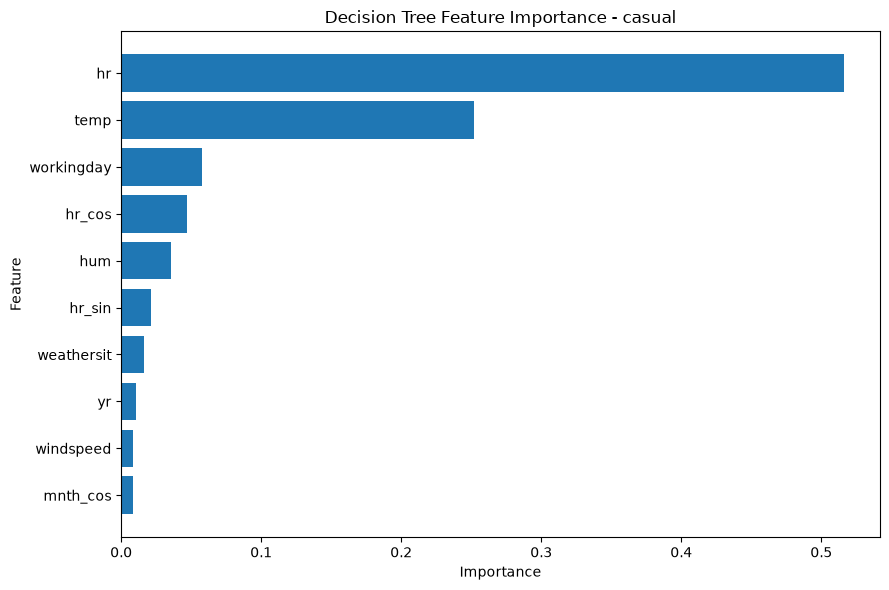


Top 10 features for registered:


,feature,importance,target
0,hr,0.6237,registered
7,workingday,0.0814,registered
8,temp,0.0754,registered
12,hr_cos,0.0714,registered
11,hr_sin,0.0553,registered
5,yr,0.0278,registered
4,weathersit,0.0127,registered
3,season,0.0111,registered
9,hum,0.0104,registered
1,mnth,0.0062,registered


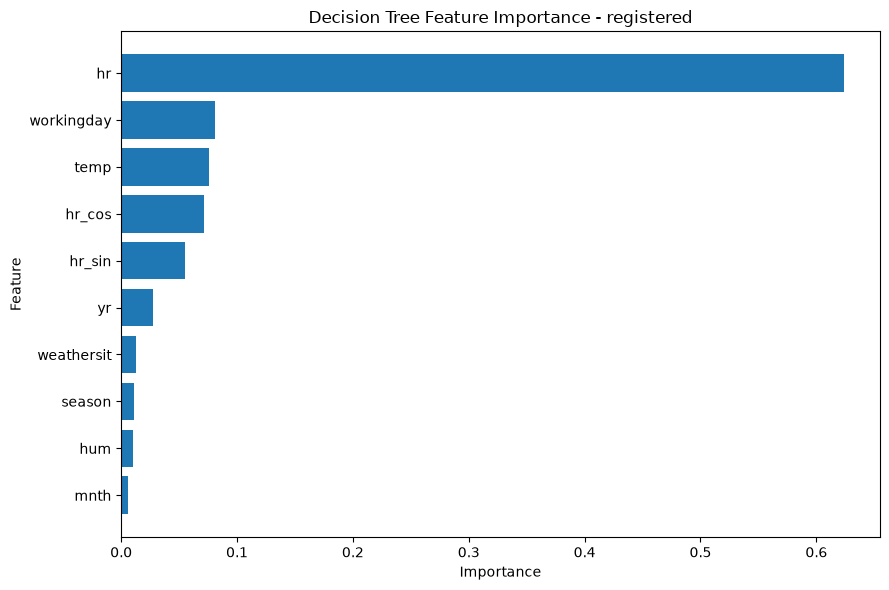


Top 10 features for cnt:


,feature,importance,target
0,hr,0.6117,cnt
8,temp,0.0939,cnt
12,hr_cos,0.0765,cnt
11,hr_sin,0.0636,cnt
7,workingday,0.0500,cnt
5,yr,0.0239,cnt
4,weathersit,0.0151,cnt
9,hum,0.0149,cnt
3,season,0.0122,cnt
10,windspeed,0.0096,cnt


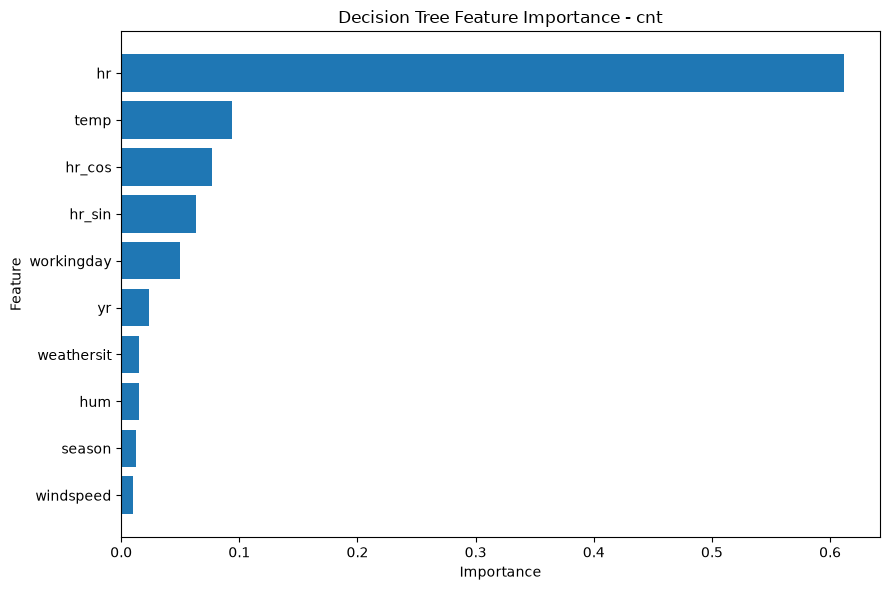

Feature importance results and plots saved!


In [48]:
# DECISION TREE FEATURE IMPORTANCE

feature_importance_results = []

for target, model in dt_best_models.items():

    importance = model.regressor_.feature_importances_

    importance_df = pd.DataFrame({
        "feature": FEATURES,
        "importance": importance,
        "target": target
    })

    importance_df = importance_df.sort_values(
        "importance",
        ascending=False
    )

    feature_importance_results.append(importance_df)

    print(f"\nTop 10 features for {target}:")
    display(importance_df.head(10).round(4))

    # Plot top 10
    top_features = importance_df.head(10).sort_values(
        "importance"
    )

    plt.figure(figsize=(9, 6))
    plt.barh(
        top_features["feature"],
        top_features["importance"]
    )
    plt.title(f"Decision Tree Feature Importance - {target}")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / f"decision_tree_importance_{target}.png",
        dpi=300
    )
    plt.show()

# Save all feature importance results
all_importance = pd.concat(
    feature_importance_results,
    ignore_index=True
)

all_importance.to_csv(
    OUTPUT_DIR / "decision_tree_feature_importance.csv",
    index=False
)

print("Feature importance results and plots saved!")

In [49]:
# RANDOM FOREST - BASELINE MODELS

rf_baseline_results = []
rf_baseline_models = {}
rf_baseline_predictions = test[
    ["datetime", "casual", "registered", "cnt"]
].copy()

for target in TARGETS:

    print(f"\nTraining Random Forest for: {target}")

    # Transform target
    y_train = np.log1p(train[target])

    # Create baseline Random Forest
    rf_model = RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    # Train model
    rf_model.fit(X_train, y_train)

    # Predict and reverse transformation
    pred_log = rf_model.predict(X_test)
    predictions = np.maximum(np.expm1(pred_log), 0)

    # Calculate metrics
    results = {
        "model": "Random Forest Baseline",
        "target": target,
        "RMSE": np.sqrt(
            mean_squared_error(test[target], predictions)
        ),
        "MAE": mean_absolute_error(
            test[target], predictions
        ),
        "RMSLE": np.sqrt(
            mean_squared_log_error(test[target], predictions)
        )
    }

    rf_baseline_results.append(results)
    rf_baseline_models[target] = rf_model
    rf_baseline_predictions[f"rf_baseline_{target}"] = predictions

# Display results
rf_baseline_df = pd.DataFrame(rf_baseline_results)
display(rf_baseline_df.round(4))


Training Random Forest for: casual

Training Random Forest for: registered

Training Random Forest for: cnt


,model,target,RMSE,MAE,RMSLE
0,Random Forest Baseline,casual,24.1049,12.3058,0.6070
1,Random Forest Baseline,registered,72.1073,47.8846,0.4784
2,Random Forest Baseline,cnt,88.1643,58.5739,0.4653


In [50]:
rf_baseline_df.to_csv(
    OUTPUT_DIR / "random_forest_baseline_metrics.csv",
    index=False
)

rf_baseline_predictions.to_csv(
    OUTPUT_DIR / "random_forest_baseline_predictions.csv",
    index=False
)

print("Random Forest baseline results saved!")

Random Forest baseline results saved!


In [51]:
# Compare Decision Tree and Random Forest baselines

baseline_comparison = pd.concat(
    [baseline_df, rf_baseline_df],
    ignore_index=True
)

display(
    baseline_comparison.pivot(
        index="target",
        columns="model",
        values="RMSE"
    ).round(4)
)

model,Decision Tree Baseline,Random Forest Baseline
target,,
casual,35.2923,24.1049
cnt,95.4975,88.1643
registered,89.7426,72.1073


In [52]:
# RANDOM FOREST HYPERPARAMETER TUNING

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.compose import TransformedTargetRegressor

rf_time_split = TimeSeriesSplit(n_splits=5)

rf_param_grid = {
    "regressor__n_estimators": [100, 200],
    "regressor__max_depth": [10, 20, None],
    "regressor__min_samples_split": [2, 10],
    "regressor__min_samples_leaf": [1, 5]
}

rf_tuning_results = []
rf_best_models = {}

for target in TARGETS:

    print(f"\nTuning Random Forest for: {target}")

    rf_model = TransformedTargetRegressor(
        regressor=RandomForestRegressor(
            random_state=42,
            n_jobs=1
        ),
        func=np.log1p,
        inverse_func=inverse_log_transform
    )

    grid_search = GridSearchCV(
        estimator=rf_model,
        param_grid=rf_param_grid,
        scoring="neg_root_mean_squared_error",
        cv=rf_time_split,
        n_jobs=-1,
        return_train_score=True
    )

    # Train using training data only
    grid_search.fit(X_train, train[target])

    # Save best model
    rf_best_models[target] = grid_search.best_estimator_

    # Evaluate on held-out test data
    predictions = grid_search.predict(X_test)

    test_rmse = np.sqrt(
        mean_squared_error(test[target], predictions)
    )

    test_mae = mean_absolute_error(
        test[target], predictions
    )

    test_rmsle = np.sqrt(
        mean_squared_log_error(
            test[target],
            np.maximum(predictions, 0)
        )
    )

    rf_tuning_results.append({
        "target": target,
        "best_cv_RMSE": -grid_search.best_score_,
        "test_RMSE": test_rmse,
        "test_MAE": test_mae,
        "test_RMSLE": test_rmsle,
        "best_params": grid_search.best_params_
    })

    print("Best CV RMSE:", round(-grid_search.best_score_, 4))
    print("Best parameters:", grid_search.best_params_)
    print("Test RMSE:", round(test_rmse, 4))

rf_tuning_df = pd.DataFrame(rf_tuning_results)

display(rf_tuning_df)


Tuning Random Forest for: casual
Best CV RMSE: 24.8691
Best parameters: {'regressor__max_depth': None, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 100}
Test RMSE: 24.1049

Tuning Random Forest for: registered
Best CV RMSE: 70.5101
Best parameters: {'regressor__max_depth': None, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 100}
Test RMSE: 72.1073

Tuning Random Forest for: cnt
Best CV RMSE: 89.3934
Best parameters: {'regressor__max_depth': None, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 100}
Test RMSE: 88.1643


,target,best_cv_RMSE,test_RMSE,test_MAE,test_RMSLE,best_params
0,casual,24.869110,24.104930,12.305754,0.607018,"{'regressor__max_depth': None, 'regressor__min..."
1,registered,70.510076,72.107279,47.884570,0.478352,"{'regressor__max_depth': None, 'regressor__min..."
2,cnt,89.393439,88.164303,58.573939,0.465340,"{'regressor__max_depth': None, 'regressor__min..."


In [53]:
rf_tuning_df.to_csv(
    OUTPUT_DIR / "random_forest_tuning_metrics.csv",
    index=False
)

print("Random Forest tuning results saved!")

Random Forest tuning results saved!


In [54]:
import joblib

rf_predictions = test[["datetime"]].copy()

for target, model in rf_best_models.items():

    # Save trained model
    joblib.dump(
        model,
        OUTPUT_DIR / f"random_forest_best_{target}.joblib"
    )

    # Save predictions
    rf_predictions[f"rf_tuned_{target}"] = model.predict(X_test)

# Save metrics and predictions
rf_tuning_df.to_csv(
    OUTPUT_DIR / "random_forest_tuning_metrics.csv",
    index=False
)

rf_predictions.to_csv(
    OUTPUT_DIR / "random_forest_tuned_predictions.csv",
    index=False
)

print("All tuned Random Forest models and predictions saved!")

All tuned Random Forest models and predictions saved!



Top 10 Random Forest features for casual:


,feature,importance,target
0,hr,0.4754,casual
8,temp,0.2450,casual
7,workingday,0.0533,casual
12,hr_cos,0.0514,casual
9,hum,0.0492,casual
10,windspeed,0.0222,casual
11,hr_sin,0.0217,casual
4,weathersit,0.0169,casual
14,mnth_cos,0.0114,casual
5,yr,0.0109,casual


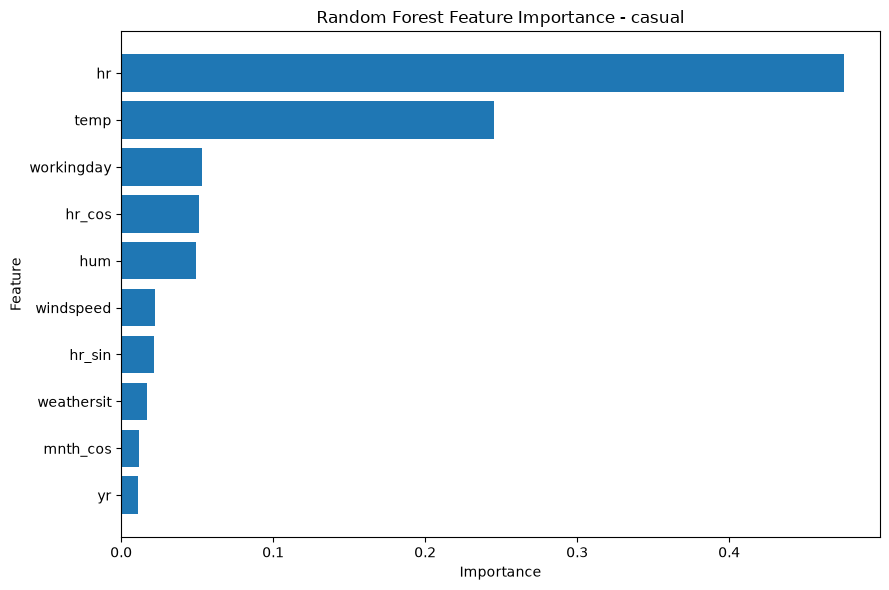


Top 10 Random Forest features for registered:


,feature,importance,target
0,hr,0.6089,registered
7,workingday,0.0771,registered
8,temp,0.0747,registered
12,hr_cos,0.0747,registered
11,hr_sin,0.0585,registered
5,yr,0.0273,registered
9,hum,0.0151,registered
4,weathersit,0.0125,registered
3,season,0.0113,registered
10,windspeed,0.0090,registered


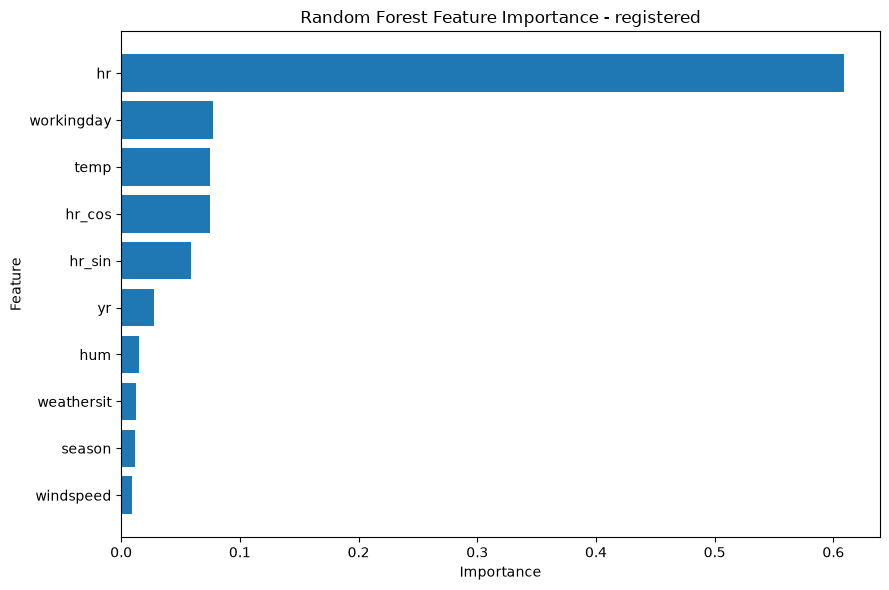


Top 10 Random Forest features for cnt:


,feature,importance,target
0,hr,0.6204,cnt
8,temp,0.0951,cnt
12,hr_cos,0.0756,cnt
11,hr_sin,0.0528,cnt
7,workingday,0.0508,cnt
5,yr,0.0232,cnt
9,hum,0.0171,cnt
4,weathersit,0.0142,cnt
3,season,0.0114,cnt
10,windspeed,0.0092,cnt


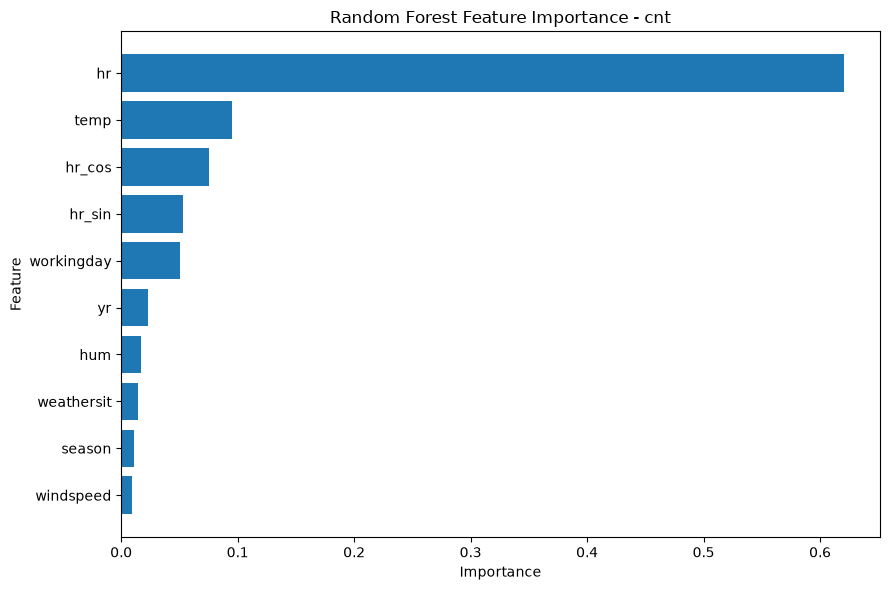

Random Forest feature importance results saved!


In [55]:
# RANDOM FOREST FEATURE IMPORTANCE

rf_importance_results = []

for target, model in rf_best_models.items():

    importance = model.regressor_.feature_importances_

    importance_df = pd.DataFrame({
        "feature": FEATURES,
        "importance": importance,
        "target": target
    })

    importance_df = importance_df.sort_values(
        "importance",
        ascending=False
    )

    rf_importance_results.append(importance_df)

    print(f"\nTop 10 Random Forest features for {target}:")
    display(importance_df.head(10).round(4))

    # Plot top 10 features
    top_features = importance_df.head(10).sort_values(
        "importance"
    )

    plt.figure(figsize=(9, 6))
    plt.barh(
        top_features["feature"],
        top_features["importance"]
    )

    plt.title(f"Random Forest Feature Importance - {target}")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / f"random_forest_importance_{target}.png",
        dpi=300
    )

    plt.show()

# Combine and save results
rf_all_importance = pd.concat(
    rf_importance_results,
    ignore_index=True
)

rf_all_importance.to_csv(
    OUTPUT_DIR / "random_forest_feature_importance.csv",
    index=False
)

print("Random Forest feature importance results saved!")

In [56]:
# FINAL TREE MODEL COMPARISON

# Add model names to tuning results
dt_tuned_comparison = dt_tuning_df[
    ["target", "test_RMSE", "test_MAE", "test_RMSLE"]
].copy()
dt_tuned_comparison["model"] = "Tuned Decision Tree"

rf_tuned_comparison = rf_tuning_df[
    ["target", "test_RMSE", "test_MAE", "test_RMSLE"]
].copy()
rf_tuned_comparison["model"] = "Tuned Random Forest"

# Standardize baseline result columns
dt_baseline_comparison = baseline_df[
    ["target", "RMSE", "MAE", "RMSLE"]
].copy()
dt_baseline_comparison.columns = [
    "target", "test_RMSE", "test_MAE", "test_RMSLE"
]
dt_baseline_comparison["model"] = "Baseline Decision Tree"

rf_baseline_comparison = rf_baseline_df[
    ["target", "RMSE", "MAE", "RMSLE"]
].copy()
rf_baseline_comparison.columns = [
    "target", "test_RMSE", "test_MAE", "test_RMSLE"
]
rf_baseline_comparison["model"] = "Baseline Random Forest"

# Combine all four models
final_tree_comparison = pd.concat(
    [
        dt_baseline_comparison,
        dt_tuned_comparison,
        rf_baseline_comparison,
        rf_tuned_comparison
    ],
    ignore_index=True
)

# Sort and display
final_tree_comparison = final_tree_comparison.sort_values(
    ["target", "test_RMSE"]
)

display(final_tree_comparison.round(4))

# Save comparison
final_tree_comparison.to_csv(
    OUTPUT_DIR / "final_tree_model_comparison.csv",
    index=False
)

print("Final tree model comparison saved!")

,target,test_RMSE,test_MAE,test_RMSLE,model
6,casual,24.1049,12.3058,0.6070,Baseline Random Forest
9,casual,24.1049,12.3058,0.6070,Tuned Random Forest
3,casual,27.7425,14.5423,0.7291,Tuned Decision Tree
0,casual,35.2923,17.9165,0.9379,Baseline Decision Tree
8,cnt,88.1643,58.5739,0.4653,Baseline Random Forest
11,cnt,88.1643,58.5739,0.4653,Tuned Random Forest
2,cnt,95.4975,59.5073,0.5851,Baseline Decision Tree
5,cnt,99.9785,63.2926,0.5829,Tuned Decision Tree
10,registered,72.1073,47.8846,0.4784,Tuned Random Forest
7,registered,72.1073,47.8846,0.4784,Baseline Random Forest


Final tree model comparison saved!


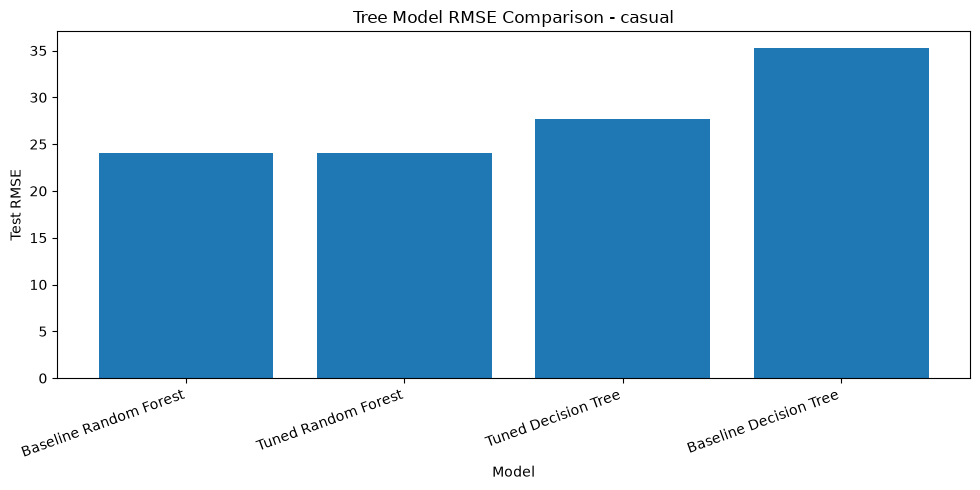

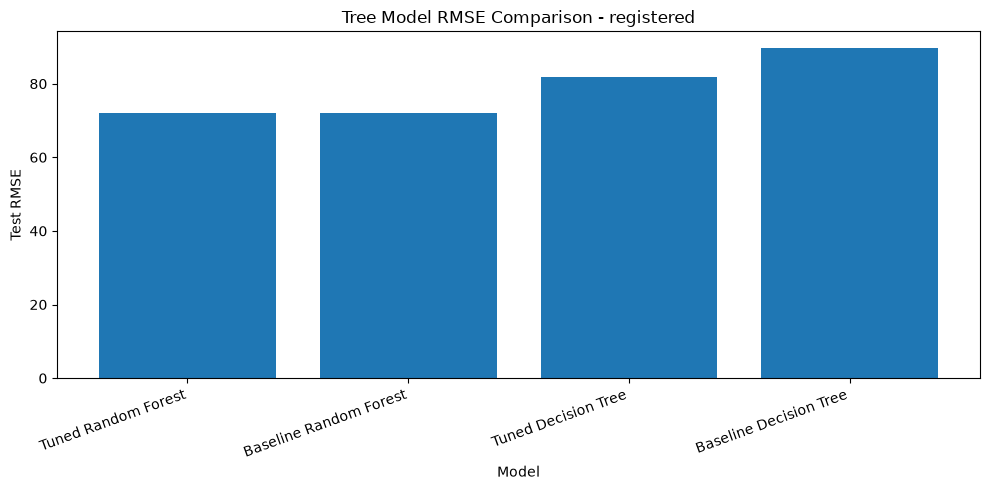

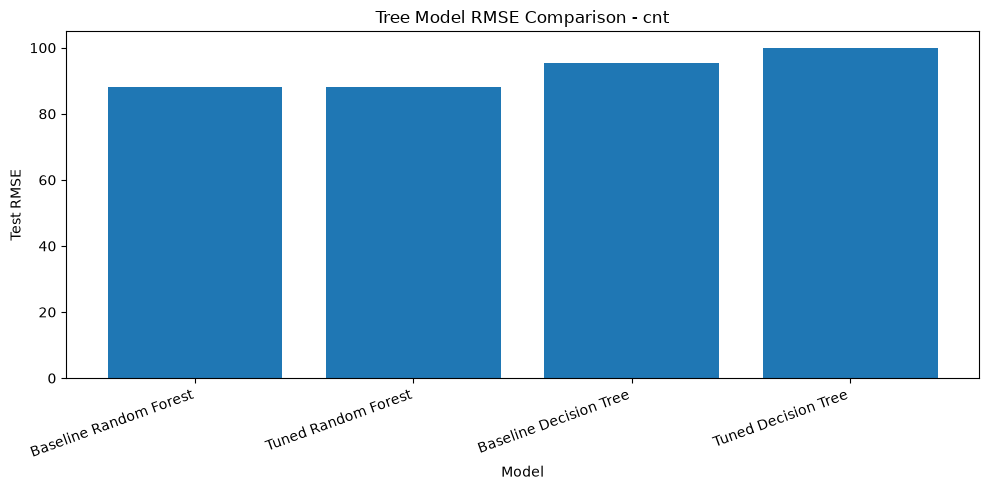

Comparison charts saved!


In [57]:
# TREE MODEL RMSE COMPARISON

for target in TARGETS:

    target_results = final_tree_comparison[
        final_tree_comparison["target"] == target
    ]

    plt.figure(figsize=(10, 5))

    plt.bar(
        target_results["model"],
        target_results["test_RMSE"]
    )

    plt.title(f"Tree Model RMSE Comparison - {target}")
    plt.ylabel("Test RMSE")
    plt.xlabel("Model")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / f"tree_model_comparison_{target}.png",
        dpi=300
    )

    plt.show()

print("Comparison charts saved!")

In [58]:
# Compare direct total predictions with summed casual + registered predictions

sum_comparison = []

for model_name, predictions_df, prefix in [
    ("Tuned Decision Tree", dt_predictions, "dt_tuned"),
    ("Tuned Random Forest", rf_predictions, "rf_tuned")
]:
    actual = test["cnt"]

    # Add casual and registered predictions
    summed_predictions = (
        predictions_df[f"{prefix}_casual"] +
        predictions_df[f"{prefix}_registered"]
    )

    # Direct prediction of total rentals
    direct_predictions = predictions_df[f"{prefix}_cnt"]

    for approach, predictions in [
        ("Separate casual + registered", summed_predictions),
        ("Direct cnt prediction", direct_predictions)
    ]:
        sum_comparison.append({
            "model": model_name,
            "approach": approach,
            "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
            "MAE": mean_absolute_error(actual, predictions),
            "RMSLE": np.sqrt(mean_squared_log_error(
                actual, np.maximum(predictions, 0)
            ))
        })

sum_comparison_df = pd.DataFrame(sum_comparison)

display(sum_comparison_df.round(4))

sum_comparison_df.to_csv(
    OUTPUT_DIR / "summed_vs_direct_predictions.csv",
    index=False
)

print("Summed vs. direct comparison saved!")

,model,approach,RMSE,MAE,RMSLE
0,Tuned Decision Tree,Separate casual + registered,91.4513,59.4217,0.5197
1,Tuned Decision Tree,Direct cnt prediction,99.9785,63.2926,0.5829
2,Tuned Random Forest,Separate casual + registered,82.9772,56.4501,0.4615
3,Tuned Random Forest,Direct cnt prediction,88.1643,58.5739,0.4653


Summed vs. direct comparison saved!


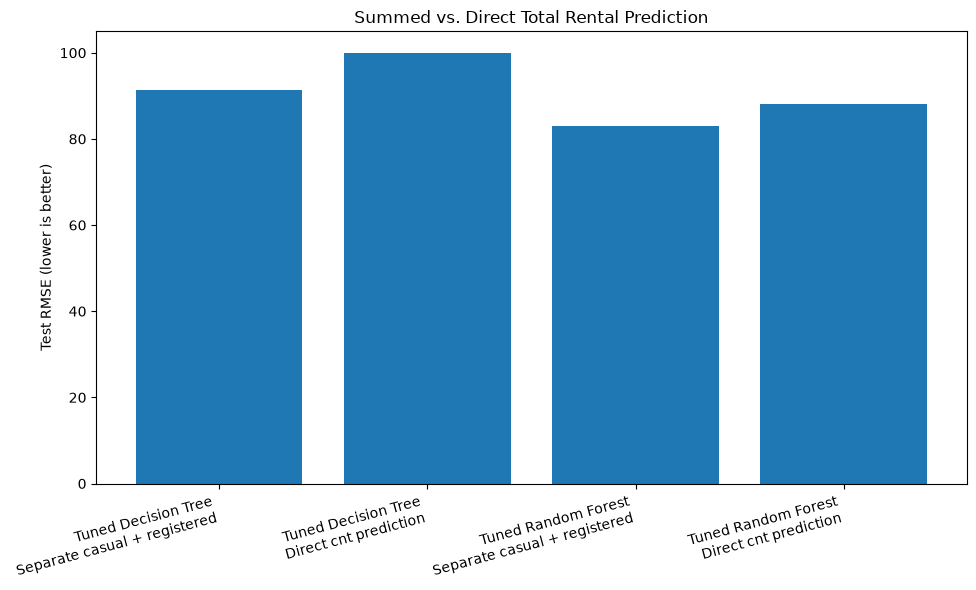

In [59]:
# Plot summed vs. direct total rental prediction

plt.figure(figsize=(10, 6))

labels = (
    sum_comparison_df["model"] + "\n" +
    sum_comparison_df["approach"]
)

plt.bar(labels, sum_comparison_df["RMSE"])

plt.title("Summed vs. Direct Total Rental Prediction")
plt.ylabel("Test RMSE (lower is better)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "summed_vs_direct_rmse.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()